# QA System Jamu Madura: IndoBERT-NER + Hybrid Retrieval (TF-IDF x Sentence-BERT) + RAG Gemini

Satu notebook, satu alur (entitas NER: KHASIAT, KANDUNGAN, JENIS):

```
Dataset 322 jamu -> Knowledge base --+--> Dataset NER -> IndoBERT-NER -> Evaluasi NER (P/R/F1, confusion matrix)
                                     |                         |
                                     |                         v
                                     +--> Indeks TF-IDF + SBERT        Query -> ekstraksi khasiat (NER)
                                                  |                          |
                                                  +---------> Hybrid retrieval <---+
                                                                   |
                                                           Top-K -> Konteks -> Gemini -> Jawaban
                                                                   |
                                                         Evaluasi retrieval dan RAG
```

Bagian yang paling penting untuk diverifikasi manual ada di bagian **Catatan** di akhir notebook.

In [2]:
# Jalankan sekali jika belum terpasang
%pip install -q transformers torch seqeval sentence-transformers scikit-learn matplotlib pandas numpy nltk bert-score google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, re, json, time, random, getpass
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- konfigurasi ----------------
CSV_PATH        = "data_jamu_322.csv"
NER_MODEL_NAME  = "indobenchmark/indobert-base-p1"        # untuk NER
SBERT_NAME      = "LazarusNLP/all-indobert-base-v4"       # encoder kalimat berbasis IndoBERT (lihat catatan di akhir)
BERTSCORE_MODEL = ("indobenchmark/indobert-base-p1", 9)   # (model, layer) untuk BERTScore
GEMINI_MODELS   = ["gemini-3.6-flash"] # urutan prioritas; model yang tidak ada akan dilewati
INCLUDE_NAME_IN_DOC = True      # True: dokumen = "Nama (jenis: ...): khasiat. Kandungan: ..."
USE_JENIS      = True           # True: kolom JENIS ikut masuk dokumen dan konteks Gemini
USE_KANDUNGAN  = True           # True: kolom KANDUNGAN ikut masuk dokumen dan konteks Gemini

ENTITY_TYPES = ["KHASIAT", "KANDUNGAN", "JENIS"]
LABELS     = ["O"] + [f"{p}-{t}" for t in ENTITY_TYPES for p in ("B", "I")]   # 7 label
MAX_LEN    = 192
NUM_EPOCHS = 15
LR         = 3e-5
BATCH      = 8
TOP_K      = 5
SEED       = 42
NER_DIR    = "ner_model_v2"   # model 7 label; folder lama ner_model/ (3 label) tidak kompatibel
RETRAIN_NER = True              # harus True saat pertama kali (label berubah); False = pakai model di NER_DIR jika sudah ada
GEN_SLEEP   = 4                 # jeda antar panggilan Gemini (detik) agar tidak kena rate limit

random.seed(SEED); np.random.seed(SEED)

## 1. Knowledge base
Satu dokumen per jamu: `"Nama (jenis: ...): khasiat. Kandungan: ..."`. Nama ikut masuk supaya Gemini tahu jamu mana yang dimaksud.
Nilai kosong (kosong, NaN, `-`) di kedua kolom itu diganti **"Tidak ada"** dan tetap tampil di dokumen dan konteks Gemini, tetapi tidak dijadikan anotasi NER maupun pertanyaan evaluasi.
Kolom **JENIS** dan **KANDUNGAN** dari CSV ikut dipakai (matikan lewat `USE_JENIS` / `USE_KANDUNGAN` di sel konfigurasi untuk ablasi).
Nama kolom dicari otomatis (huruf besar/kecil tidak berpengaruh); jika tidak ketemu, sel ini berhenti dengan pesan yang menampilkan kolom yang ada.

In [4]:
raw = pd.read_csv(CSV_PATH)
print("Kolom di CSV:", list(raw.columns))

def clean_text(s):
    return re.sub(r"\s+", " ", str(s)).strip()

NO_VALUE = "Tidak ada"                      # pengganti nilai kosong di kolom JENIS dan KANDUNGAN
EMPTY_VALUES = {"", "-", "--", "nan", "none", "null", "tidak ada"}
def clean_opt(v):
    """Nilai kolom JENIS/KANDUNGAN: kosong, NaN, '-' (dan variasi 'tidak ada') diseragamkan menjadi NO_VALUE."""
    if pd.isna(v): return NO_VALUE
    s = clean_text(v)
    return NO_VALUE if s.lower() in EMPTY_VALUES else s

def has_value(v):
    """True jika nilainya benar-benar ada (bukan kosong dan bukan 'Tidak ada'). Dipakai untuk anotasi NER dan pertanyaan evaluasi."""
    return bool(v) and v != NO_VALUE

def find_col(df, key):
    """Cari kolom yang namanya memuat `key` (tanpa peduli huruf besar/kecil/spasi)."""
    return next((c for c in df.columns if key in str(c).lower().replace(" ", "")), None)

COL_JENIS, COL_KANDUNGAN = find_col(raw, "jenis"), find_col(raw, "kandungan")
for flag, col, name in [(USE_JENIS, COL_JENIS, "JENIS"), (USE_KANDUNGAN, COL_KANDUNGAN, "KANDUNGAN")]:
    if flag and col is None:
        raise ValueError(f"Kolom {name} tidak ditemukan di CSV. Kolom yang ada: {list(raw.columns)}. "
                         f"Periksa nama kolom, atau set USE_{name}=False.")

kb = raw[["NO", "NAMA JAMU", "KHASIAT"]].copy()
kb.columns = ["doc_id", "nama", "khasiat"]
kb["jenis"]     = raw[COL_JENIS].map(clean_opt)     if USE_JENIS     else ""
kb["kandungan"] = raw[COL_KANDUNGAN].map(clean_opt) if USE_KANDUNGAN else ""
kb["nama"]    = kb["nama"].map(clean_text).str.title()
kb["khasiat"] = kb["khasiat"].map(clean_text)
kb["khasiat"] = kb["khasiat"].str[0].str.upper() + kb["khasiat"].str[1:]
kb = kb.drop_duplicates(subset=["nama", "khasiat"]).reset_index(drop=True)

def build_doc(r):
    if not INCLUDE_NAME_IN_DOC:
        text = r["khasiat"]
    else:
        head = r["nama"] + (f" (jenis: {r['jenis']})" if r["jenis"] else "")
        text = f"{head}: {r['khasiat']}"
    if r["kandungan"]:
        text = text.rstrip(". ") + f". Kandungan: {r['kandungan']}"
    return text

kb["doc_text"] = kb.apply(build_doc, axis=1)
kb[["doc_id", "nama", "jenis", "kandungan", "khasiat", "doc_text"]].to_csv("knowledge_base.csv", index=False)
print("Jumlah dokumen:", len(kb),
      "| JENIS terisi:", int(kb["jenis"].map(has_value).sum()), f"(\"{NO_VALUE}\": {int((kb['jenis'] == NO_VALUE).sum())})",
      "| KANDUNGAN terisi:", int(kb["kandungan"].map(has_value).sum()), f"(\"{NO_VALUE}\": {int((kb['kandungan'] == NO_VALUE).sum())})")
print("Rata-rata panjang dokumen (kata):", round(kb["doc_text"].str.split().str.len().mean(), 1))
print("Contoh doc_text:", kb["doc_text"].iloc[0])
kb.head(3)

Kolom di CSV: ['NO', 'NAMA JAMU', 'KHASIAT', 'KANDUNGAN', 'ATURAN MINUM', 'EFEK SAMPING', 'JENIS', 'PRODUSEN', 'KATEGORI', 'LOKASI PEMASARAN', 'LOKASI PRODUKSI', 'KABUPATEN', 'PERIZINAN']
Jumlah dokumen: 322 | JENIS terisi: 302 ("Tidak ada": 20) | KANDUNGAN terisi: 285 ("Tidak ada": 37)
Rata-rata panjang dokumen (kata): 29.5
Contoh doc_text: Galian Rapat Wangi (jenis: pil): Mengurangi bau badan, mengurangi bau tidak sedap serta membuat rapet dan keset area kewanitaan. Kandungan: kunci, kunyit, pinang muda parabes


,doc_id,nama,khasiat,jenis,kandungan,doc_text
0,1,Galian Rapat Wangi,"Mengurangi bau badan, mengurangi bau tidak sed...",pil,"kunci, kunyit, pinang muda parabes",Galian Rapat Wangi (jenis: pil): Mengurangi ba...
1,2,Empot-Empot Legit,"Mengurangi lendir berlebih, mengatasi keputiha...",pil,"kunci, kunyit, pinang muda parabes",Empot-Empot Legit (jenis: pil): Mengurangi len...
2,3,Galian Singset,"Mengurangi lemak dalam tubuh, menambah nafsu m...",pil,"kunyit, daun sirih, delima putih",Galian Singset (jenis: pil): Mengurangi lemak ...


## 2. Set evaluasi (satu file untuk retrieval, NER, dan generasi)
Setiap baris `eval_set.csv`: pertanyaan, dokumen relevan (untuk MRR/Precision/Recall), span khasiat di pertanyaan
(untuk uji NER), dan jawaban referensi (untuk BLEU/ROUGE/BERTScore).

Set awal ini **hanya 18 pertanyaan** dan dokumen relevannya dilabeli otomatis lewat kata kunci. Perluas ke 50-100
pertanyaan dan periksa manual sebelum dipakai di skripsi. Jangan ubah `eval_set.csv` yang sudah kamu edit: sel ini tidak menimpanya.

Selain itu, **`eval_set_kandungan_jenis.csv`** dibuat otomatis dari knowledge base: pertanyaan tentang kandungan, jenis, dan kombinasinya dengan khasiat
(kolom `qtype`). Relevansi dan span-nya berbasis kecocokan item persis, jadi **periksa dan tambahkan pertanyaan tulisan sendiri**,
terutama yang berbahasa awam.

In [5]:
# (pertanyaan, regex untuk melabeli dokumen relevan, jawaban referensi, span khasiat di pertanyaan)
SEED_EVAL = [
    ("Jamu apa yang bisa mengatasi keputihan?",                 r"keputihan",               "Jamu untuk mengatasi keputihan",              ["mengatasi keputihan"]),
    ("Jamu untuk ibu menyusui supaya ASI lancar?",              r"\basi\b",                 "Jamu untuk melancarkan ASI",                  ["ASI lancar"]),
    ("Anak saya susah makan, jamu apa yang cocok?",             r"nafsu makan",             "Jamu untuk menambah nafsu makan",             ["susah makan"]),
    ("Badan saya bau keringat, ada jamu yang bisa membantu?",   r"bau badan|bau keringat",  "Jamu untuk mengurangi bau badan",             ["bau keringat"]),
    ("Jamu untuk perut nyeri saat datang bulan?",               r"haid|menstruasi",         "Jamu untuk mengurangi nyeri haid",            ["nyeri saat datang bulan"]),
    ("Jamu apa untuk menambah tenaga dan stamina?",             r"stamina",                 "Jamu untuk menambah stamina",                 ["menambah tenaga dan stamina"]),
    ("Pegal-pegal di badan bagusnya minum jamu apa?",           r"pegal|linu",              "Jamu untuk meredakan pegal dan linu",         ["Pegal-pegal di badan"]),
    ("Jamu untuk batuk dan pilek?",                             r"batuk|pilek",             "Jamu untuk mengatasi batuk dan pilek",        ["batuk dan pilek"]),
    ("Jamu untuk kesehatan kulit dan wajah?",                   r"\bkulit\b|jerawat|flek",  "Jamu untuk merawat kulit",                    ["kesehatan kulit dan wajah"]),
    ("Jamu untuk asam urat?",                                   r"asam urat",               "Jamu untuk mengatasi asam urat",              ["asam urat"]),
    ("Jamu yang bisa menurunkan kolesterol?",                   r"kolesterol",              "Jamu untuk menurunkan kolesterol",            ["menurunkan kolesterol"]),
    ("Jamu untuk sakit maag dan lambung?",                      r"maag|lambung",            "Jamu untuk mengatasi maag",                   ["sakit maag dan lambung"]),
    ("Jamu untuk memperbesar atau mengencangkan payudara?",     r"payudara",                "Jamu untuk perawatan payudara",               ["memperbesar atau mengencangkan payudara"]),
    ("Jamu agar badan tidak gampang masuk angin?",              r"masuk angin",             "Jamu untuk mengatasi masuk angin",            ["tidak gampang masuk angin"]),
    ("Jamu penguat kejantanan pria?",                           r"kejantanan|ereksi|sperma|lelaki|pria", "Jamu untuk kesehatan pria",      ["penguat kejantanan pria"]),
    ("Jamu untuk mengurangi lemak dan menurunkan berat badan?", r"lemak|langsing|singset",  "Jamu untuk mengurangi lemak",                 ["mengurangi lemak", "menurunkan berat badan"]),
    ("Jamu untuk gatal-gatal?",                                 r"gatal",                   "Jamu untuk mengatasi gatal",                  ["gatal-gatal"]),
    ("Jamu untuk ibu setelah melahirkan?",                      r"melahirkan|bersalin|nifas", "Jamu perawatan pasca melahirkan",           ["setelah melahirkan"]),
]

# ---------- helper entitas (dipakai juga di bagian 3) ----------
def parse_span(s):
    """'KANDUNGAN:kunyit' -> ('KANDUNGAN', 'kunyit'); tanpa awalan = KHASIAT."""
    if isinstance(s, tuple): return s
    s = str(s).strip()
    head, sep, rest = s.partition(":")
    if sep and head.strip().upper() in ENTITY_TYPES:
        return (head.strip().upper(), rest.strip())
    return ("KHASIAT", s)

def parse_span_cell(cell):
    """Isi kolom ner_spans/spans ('a | KANDUNGAN:b') -> [(label, teks), ...]."""
    if pd.isna(cell): return []
    return [parse_span(x) for x in str(cell).split("|") if x.strip()]

ITEM_SEP_DAN = re.compile(r"[,;/\n+&]|\b(?:dan|serta|juga)\b", re.I)
ITEM_SEP     = re.compile(r"[,;/\n+&]")
def auto_items(text, split_dan=True):
    """Pecah daftar kandungan/jenis menjadi item (pra-anotasi otomatis; PERIKSA hasilnya)."""
    items = []
    for seg in (ITEM_SEP_DAN if split_dan else ITEM_SEP).split(str(text)):
        seg = re.sub(r"\s+", " ", seg).strip(" ,.;:-")
        if seg: items.append(seg)
    return items

# ---------- set evaluasi dasar (khasiat) ----------
if not os.path.exists("eval_set.csv"):
    rows = []
    for i, (q, pat, ref, spans) in enumerate(SEED_EVAL, 1):
        hit = kb[kb["khasiat"].str.contains(pat, case=False, regex=True)]
        rows.append({"qid": i, "question": q, "relevant_ids": "|".join(map(str, hit["doc_id"])),
                     "n_relevant": len(hit), "ner_spans": " | ".join(spans), "reference_answer": ref})
    pd.DataFrame(rows).to_csv("eval_set.csv", index=False)
ev_base = pd.read_csv("eval_set.csv")
if "qtype" not in ev_base: ev_base["qtype"] = "khasiat"

# ---------- pertanyaan KANDUNGAN, JENIS, dan kombinasi (dibuat otomatis dari knowledge base) ----------
# Format kolom ner_spans: 'KANDUNGAN:kunyit | asam urat' (tanpa awalan = KHASIAT). Relevansi = item kandungan/jenis
# persis sama (huruf besar/kecil diabaikan). File ini tidak ditimpa jika sudah ada: PERIKSA dan tambah pertanyaan sendiri.
EVAL_EXTRA_FILE = "eval_set_kandungan_jenis.csv"
EXTRA_COLS = ["qid", "question", "relevant_ids", "n_relevant", "ner_spans", "reference_answer", "qtype"]

def has_item(series, item, split_dan=True):
    return series.map(lambda v: item in [x.lower() for x in auto_items(v, split_dan)])

def top_items(series, split_dan=True, n=8, min_docs=2):
    c = Counter()
    for v in series:
        if not has_value(v): continue                 # lewati "Tidak ada"
        for it in set(x.lower() for x in auto_items(v, split_dan)): c[it] += 1
    return [it for it, k in c.most_common() if k >= min_docs and len(it) >= 3][:n]

KH_COMBO = [(SEED_EVAL[i][1], SEED_EVAL[i][3][0]) for i in (9, 10, 7)]    # (regex relevansi khasiat, span khasiat)

if not os.path.exists(EVAL_EXTRA_FILE) and (USE_KANDUNGAN or USE_JENIS):
    rows = []
    def add(qtype, q, rel, spans, ref):
        if len(rel) == 0: return False
        rows.append({"qid": 1000 + len(rows) + 1, "question": q, "relevant_ids": "|".join(map(str, rel["doc_id"])),
                     "n_relevant": len(rel), "ner_spans": " | ".join(spans), "reference_answer": ref, "qtype": qtype})
        return True
    ings = top_items(kb["kandungan"], True, 8) if USE_KANDUNGAN else []
    jns  = top_items(kb["jenis"], False, 4) if USE_JENIS else []
    for it in ings:
        add("kandungan", f"Jamu apa yang mengandung {it}?", kb[has_item(kb["kandungan"], it)],
            [f"KANDUNGAN:{it}"], f"Jamu yang mengandung {it}")
    for jn in jns:
        add("jenis", f"Jamu jenis {jn} apa saja?", kb[has_item(kb["jenis"], jn, False)],
            [f"JENIS:{jn}"], f"Jamu jenis {jn}")
    n_c = 0
    for it in ings[:4]:
        for pat, sp in KH_COMBO:
            m = has_item(kb["kandungan"], it) & kb["khasiat"].str.contains(pat, case=False, regex=True)
            if n_c < 6 and add("kombinasi", f"Jamu yang mengandung {it} untuk {sp}?", kb[m],
                               [f"KANDUNGAN:{it}", sp], f"Jamu yang mengandung {it} untuk {sp}"): n_c += 1
    n_c = 0
    for jn in jns[:2]:
        for pat, sp in KH_COMBO:
            m = has_item(kb["jenis"], jn, False) & kb["khasiat"].str.contains(pat, case=False, regex=True)
            if n_c < 3 and add("kombinasi", f"Jamu jenis {jn} untuk {sp}?", kb[m],
                               [f"JENIS:{jn}", sp], f"Jamu jenis {jn} untuk {sp}"): n_c += 1
    pd.DataFrame(rows, columns=EXTRA_COLS).to_csv(EVAL_EXTRA_FILE, index=False)
    print(f"{EVAL_EXTRA_FILE} dibuat ({len(rows)} pertanyaan otomatis). PERIKSA dan tambah pertanyaan tulisan sendiri.")

ev_x = pd.read_csv(EVAL_EXTRA_FILE) if os.path.exists(EVAL_EXTRA_FILE) else pd.DataFrame(columns=EXTRA_COLS)
ev = pd.concat([ev_base, ev_x], ignore_index=True)
ev["relevant_ids"] = ev["relevant_ids"].fillna("").astype(str).map(lambda s: [int(x) for x in s.split("|") if x])
ev["ner_spans"]    = ev["ner_spans"].map(parse_span_cell)                  # -> [(label, teks), ...]
print(ev["qtype"].value_counts().to_dict())
print(ev[["qid", "qtype", "question", "n_relevant"]].to_string(index=False))

eval_set_kandungan_jenis.csv dibuat (21 pertanyaan otomatis). PERIKSA dan tambah pertanyaan tulisan sendiri.
{'khasiat': 18, 'kombinasi': 9, 'kandungan': 8, 'jenis': 4}
 qid     qtype                                                 question  n_relevant
   1   khasiat                  Jamu apa yang bisa mengatasi keputihan?          57
   2   khasiat               Jamu untuk ibu menyusui supaya ASI lancar?           7
   3   khasiat              Anak saya susah makan, jamu apa yang cocok?          22
   4   khasiat    Badan saya bau keringat, ada jamu yang bisa membantu?          29
   5   khasiat                Jamu untuk perut nyeri saat datang bulan?          17
   6   khasiat              Jamu apa untuk menambah tenaga dan stamina?          34
   7   khasiat            Pegal-pegal di badan bagusnya minum jamu apa?          17
   8   khasiat                              Jamu untuk batuk dan pilek?           7
   9   khasiat                    Jamu untuk kesehatan kulit dan wajah?    

## 3. Dataset NER (tiga entitas: KHASIAT, KANDUNGAN, JENIS)

**Mengapa berbeda dari versi sebelumnya?** Pelabelan lama memakai template tetap `"jamu <nama> berkhasiat untuk <khasiat>"`
dan menandai kata lewat pengecekan substring. Akibatnya model hanya belajar aturan "semua kata setelah *berkhasiat untuk*
adalah khasiat", F1 menjadi hampir 1 tanpa arti, dan model tidak bisa menandai khasiat pada pertanyaan bebas.

Pendekatan di sini:
- Label berupa **span** (frasa), bukan kata per kata, dengan **tiga jenis entitas**: `KHASIAT` (frasa manfaat/keluhan), `KANDUNGAN` (bahan/ramuan), dan `JENIS` (jenis jamu).
  Sumber span: aturan otomatis, lalu **kamu verifikasi**: `ner_annotations.csv` (khasiat) dan `ner_annotations_extra.csv` (kandungan dan jenis; kolom `label`).
- Data latih ditambah **pertanyaan sintetis** (template + span), termasuk **kombinasi** seperti "jamu jenis X yang mengandung Y untuk Z", agar model terbiasa melihat kata pengisi dan beberapa entitas dalam satu pertanyaan.
- Split berbasis **grup teks khasiat** supaya khasiat yang sama persis tidak muncul di data latih dan uji; kalimat kandungan/jenis mengikuti split jamunya.
  Nilai `JENIS` yang jumlahnya sedikit pasti muncul di train dan test (kosakata tertutup), jadi skor JENIS cenderung tinggi dan tidak menunjukkan generalisasi.
- **Uji utama** memakai pertanyaan tulisan tangan di `eval_set.csv` dan `eval_set_kandungan_jenis.csv` (kolom `ner_spans`), karena itu yang menyerupai penggunaan nyata.

Pedoman: span khasiat = frasa manfaat/keluhan yang diatasi; kata pengantar (*untuk, agar, dapat, bisa*) dan kata pengisi pertanyaan
(*jamu apa, yang cocok, saya*) bukan bagian span; klausa dipisah koma/*serta*/*juga* menjadi span terpisah, tetapi *dan*
di dalam frasa tidak memisahkan. Kandungan: satu span per bahan (dipisah koma/titik koma/garis miring/*dan*). Jenis: satu span per jenis.

In [6]:
TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)

def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]

def _find_span(low, sp, used):
    """Kemunculan pertama `sp` yang tidak bertabrakan: utamakan batas kata, cadangan substring biasa."""
    for pat in (r"(?<!\w)" + re.escape(sp) + r"(?!\w)", re.escape(sp)):
        for m in re.finditer(pat, low):
            i, j = m.span()
            if not any(i < b and a < j for a, b in used):
                return i, j
    return None

def to_bio(text, spans):
    """Span [(label, teks) atau 'teks'] -> tag BIO per token. Mengembalikan (tokens, tags, span yang tidak ditemukan)."""
    toks = tokenize(text)
    tags = ["O"] * len(toks)
    low, used, missing = text.lower(), [], []
    parsed = sorted((parse_span(s) for s in spans), key=lambda x: -len(x[1]))   # span panjang dulu
    for label, sp in parsed:
        sp = sp.strip()
        if not sp:
            continue
        pos = _find_span(low, sp.lower(), used)
        if pos is None:
            missing.append(sp); continue
        i, j = pos; used.append((i, j)); first = True
        for k, (_, s, e) in enumerate(toks):
            if s >= i and e <= j:
                tags[k] = ("B-" if first else "I-") + label; first = False
    return [t for t, _, _ in toks], tags, missing

def decode_entities(text, tags):
    """Tag BIO per token -> daftar entitas [(label, teks), ...]."""
    toks, ents, cur = tokenize(text), [], None            # cur = [label, mulai, akhir]
    for (_, s, e), tag in zip(toks, tags):
        if tag == "O":
            if cur: ents.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B" or cur is None or cur[0] != label:
            if cur: ents.append(cur)
            cur = [label, s, e]
        else:
            cur[2] = e
    if cur: ents.append(cur)
    return [(l, text[a:b]) for l, a, b in ents]

def decode_spans(text, tags):
    return [t for _, t in decode_entities(text, tags)]

# ---- pra-anotasi otomatis ----
FILLER_START = {"untuk", "agar", "supaya", "dapat", "bisa", "guna", "yang", "dan", "serta"}
SEP_RE = re.compile(r"[,;.]|\b(?:serta|juga)\b", re.I)

def clean_clause(seg):
    words = seg.strip().split()
    while words and words[0].lower().strip(",.;") in FILLER_START: words = words[1:]
    while words and words[-1].lower().strip(",.;") in {"dan", "serta", "juga", "yang"}: words = words[:-1]
    return " ".join(words).strip(" ,.;")

def auto_spans(text):
    spans, pos = [], 0
    for m in list(SEP_RE.finditer(text)) + [None]:
        end = m.start() if m else len(text)
        seg = clean_clause(text[pos:end])
        pos = m.end() if m else len(text)
        if seg: spans.append(seg)
    return spans

kh = kb[["doc_id", "khasiat"]].rename(columns={"khasiat": "text"}).copy()
kh["spans"] = kh["text"].map(lambda t: " | ".join(auto_spans(t)))
if not os.path.exists("ner_annotations.csv"):             # file yang sudah kamu edit tidak ditimpa
    kh.to_csv("ner_annotations.csv", index=False)
    print("ner_annotations.csv dibuat. PERIKSA kolom 'spans' sebelum melatih.")
else:
    print("ner_annotations.csv sudah ada, dipakai apa adanya.")

# ---- pra-anotasi KANDUNGAN dan JENIS (satu file: ner_annotations_extra.csv) ----
EXTRA_FILE = "ner_annotations_extra.csv"
if not os.path.exists(EXTRA_FILE):                        # file yang sudah kamu edit tidak ditimpa
    xr = []
    for _, r in kb.iterrows():
        if USE_KANDUNGAN and has_value(r["kandungan"]):
            xr.append({"doc_id": r["doc_id"], "label": "KANDUNGAN", "text": r["kandungan"],
                       "spans": " | ".join(auto_items(r["kandungan"]))})
        if USE_JENIS and has_value(r["jenis"]):
            xr.append({"doc_id": r["doc_id"], "label": "JENIS", "text": r["jenis"],
                       "spans": " | ".join(auto_items(r["jenis"], split_dan=False))})
    pd.DataFrame(xr, columns=["doc_id", "label", "text", "spans"]).to_csv(EXTRA_FILE, index=False)
    print(f"{EXTRA_FILE} dibuat ({len(xr)} baris). PERIKSA kolom 'spans' sebelum melatih.")
else:
    print(f"{EXTRA_FILE} sudah ada, dipakai apa adanya.")

ner_annotations.csv dibuat. PERIKSA kolom 'spans' sebelum melatih.
ner_annotations_extra.csv dibuat (587 baris). PERIKSA kolom 'spans' sebelum melatih.


In [7]:
def _spans(label, cell):
    return [(label, x.strip()) for x in str(cell).split("|") if x.strip()] if pd.notna(cell) else []

# --- KHASIAT (ner_annotations.csv) ---
ann = pd.read_csv("ner_annotations.csv")
ann["label"] = "KHASIAT"
ann["spans"] = ann["spans"].map(lambda c: _spans("KHASIAT", c))
ann["group"] = ann["text"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()

# split berbasis grup khasiat: 80/10/10
rng = random.Random(SEED)
groups = sorted(ann["group"].unique()); rng.shuffle(groups)
n = len(groups)
g_test, g_val = set(groups[: int(0.1 * n)]), set(groups[int(0.1 * n): int(0.2 * n)])
ann["split"] = ann["group"].map(lambda g: "test" if g in g_test else "val" if g in g_val else "train")
doc_split = dict(zip(ann["doc_id"], ann["split"]))

# --- KANDUNGAN dan JENIS (ner_annotations_extra.csv): ikut split jamunya ---
ann_x = pd.read_csv(EXTRA_FILE) if os.path.exists(EXTRA_FILE) else pd.DataFrame(columns=["doc_id", "label", "text", "spans"])
use = [t for t, on in (("KANDUNGAN", USE_KANDUNGAN), ("JENIS", USE_JENIS)) if on]
ann_x = ann_x[ann_x["label"].isin(use)].copy()
ann_x["spans"] = [_spans(l, c) for l, c in zip(ann_x["label"], ann_x["spans"])]
ann_x["group"] = ann_x["label"] + " " + ann_x["text"].astype(str).str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()
ann_x["split"] = ann_x["doc_id"].map(doc_split).fillna("train")

cols = ["doc_id", "label", "text", "spans", "group", "split"]
ann_all = pd.concat([ann[cols], ann_x[cols]], ignore_index=True)

bad = [(r["label"], r["doc_id"], m) for _, r in ann_all.iterrows() for m in [to_bio(r["text"], r["spans"])[2]] if m]
print("Kalimat:", len(ann_all), "| per label:", ann_all["label"].value_counts().to_dict(),
      "| tanpa span:", int((ann_all["spans"].map(len) == 0).sum()), "| span tak ditemukan:", len(bad))
for b in bad[:10]: print("  ", b)
print(ann_all.groupby(["label", "split"]).size().unstack(fill_value=0))

TEMPLATES = [
    "Jamu apa yang bisa {s}?", "Jamu untuk {s}?", "Saya ingin {s}, jamu apa yang cocok?",
    "Ada jamu yang dapat {s}?", "Rekomendasi jamu madura untuk {s}", "Minum jamu apa agar bisa {s}?",
    "Apakah ada jamu yang berkhasiat {s}?", "Tolong carikan jamu supaya {s}", "Jamu madura apa yang dapat {s}?",
]
TEMPLATES_KAND = [
    "Jamu apa yang mengandung {s}?", "Jamu yang berbahan {s}", "Ada jamu dengan kandungan {s}?",
    "Jamu madura yang terbuat dari {s}", "Cari jamu yang memakai {s}", "Apa saja jamu berbahan dasar {s}?",
]
TEMPLATES_JENIS = [
    "Jamu jenis {s} apa saja?", "Ada jamu {s}?", "Apa saja jamu yang berjenis {s}?",
    "Rekomendasi jamu {s}", "Tampilkan jamu madura jenis {s}",
]
VERB_RE = re.compile(r"^me\w{3,}", re.I)

def lc(s):                                   # huruf awal kecil (kecuali singkatan seperti ASI)
    return s if s[:2].isupper() else s[:1].lower() + s[1:]

def make_row(text, spans, source):
    toks, tags, _ = to_bio(text, spans)
    return {"text": text, "tokens": toks, "tags": tags, "source": source, "spans": spans}

def combo_rows(df, r):
    """Satu pertanyaan kombinasi per jamu (jenis/kandungan/khasiat milik jamu yang sama)."""
    out = []
    for _, g in df.groupby("doc_id"):
        f = {lab: grp.iloc[0]["spans"] for lab, grp in g.groupby("label")}
        j = [lc(s) for _, s in f.get("JENIS", [])]
        c = [lc(s) for _, s in f.get("KANDUNGAN", [])]
        k = [lc(s) for _, s in f.get("KHASIAT", []) if VERB_RE.match(s)]
        J, C, K = (r.choice(x) if x else None for x in (j, c, k))
        opts = []
        if J and K: opts += [(f"Jamu jenis {J} yang bisa {K}?", [("JENIS", J), ("KHASIAT", K)]),
                             (f"Ada jamu {J} untuk {K}?",        [("JENIS", J), ("KHASIAT", K)])]
        if C and K: opts += [(f"Jamu yang mengandung {C} untuk {K}?", [("KANDUNGAN", C), ("KHASIAT", K)]),
                             (f"Jamu berbahan {C} yang dapat {K}",    [("KANDUNGAN", C), ("KHASIAT", K)])]
        if J and C: opts += [(f"Jamu {J} yang mengandung {C}?", [("JENIS", J), ("KANDUNGAN", C)])]
        if J and C and K:
            opts += [(f"Jamu jenis {J} dengan kandungan {C} untuk {K}?", [("JENIS", J), ("KANDUNGAN", C), ("KHASIAT", K)])]
        if opts:
            text, spans = r.choice(opts); out.append(make_row(text, spans, "sintetis"))
    return out

def build_rows(df, n_synth=2, seed=SEED):
    r, rows, seen = random.Random(seed), [], set()
    for _, a in df.iterrows():
        rows.append(make_row(a["text"], a["spans"], a["label"].lower()))
        key = (a["label"], a["group"])
        if key in seen or not a["spans"]: continue
        seen.add(key)
        if a["label"] == "KHASIAT":
            cand = [s for _, s in a["spans"] if VERB_RE.match(s)]
            for tpl in (r.sample(TEMPLATES, k=min(n_synth, len(TEMPLATES))) if cand else []):
                sp = lc(r.choice(cand)); rows.append(make_row(tpl.format(s=sp), [("KHASIAT", sp)], "sintetis"))
        elif a["label"] == "KANDUNGAN":
            for tpl in r.sample(TEMPLATES_KAND, k=min(n_synth, len(TEMPLATES_KAND))):
                items = [lc(s) for _, s in r.sample(a["spans"], k=min(len(a["spans"]), r.choice([1, 2])))]
                rows.append(make_row(tpl.format(s=" dan ".join(items)), [("KANDUNGAN", x) for x in items], "sintetis"))
        elif a["label"] == "JENIS":
            for tpl in r.sample(TEMPLATES_JENIS, k=min(n_synth, len(TEMPLATES_JENIS))):
                sp = lc(r.choice(a["spans"])[1]); rows.append(make_row(tpl.format(s=sp), [("JENIS", sp)], "sintetis"))
    rows += combo_rows(df, r)
    return rows

train_rows = build_rows(ann_all[ann_all["split"] == "train"])
val_rows   = build_rows(ann_all[ann_all["split"] == "val"],  seed=SEED + 1)
test_rows  = build_rows(ann_all[ann_all["split"] == "test"], seed=SEED + 2)
q_rows     = [make_row(r["question"], r["ner_spans"], "pertanyaan") for _, r in ev.iterrows()]

def tag_share(rows):
    t = [x for r in rows for x in r["tags"]]
    return {l: round(t.count(l) / len(t), 3) for l in LABELS}
for name, rows in [("train", train_rows), ("val", val_rows), ("test", test_rows), ("pertanyaan", q_rows)]:
    print(f"{name:11s} n={len(rows):4d}  sumber: {dict(Counter(r['source'] for r in rows))}")
    print(f"{'':11s} distribusi tag: {tag_share(rows)}")

Kalimat: 909 | per label: {'KHASIAT': 322, 'JENIS': 302, 'KANDUNGAN': 285} | tanpa span: 0 | span tak ditemukan: 0
split      test  train  val
label                      
JENIS        30    244   28
KANDUNGAN    31    226   28
KHASIAT      31    261   30
train       n=1837  sumber: {'khasiat': 261, 'sintetis': 1106, 'kandungan': 226, 'jenis': 244}
            distribusi tag: {'O': 0.384, 'B-KHASIAT': 0.081, 'I-KHASIAT': 0.287, 'B-KANDUNGAN': 0.096, 'I-KANDUNGAN': 0.126, 'B-JENIS': 0.024, 'I-JENIS': 0.001}
val         n= 235  sumber: {'khasiat': 30, 'sintetis': 149, 'kandungan': 28, 'jenis': 28}
            distribusi tag: {'O': 0.414, 'B-KHASIAT': 0.089, 'I-KHASIAT': 0.272, 'B-KANDUNGAN': 0.092, 'I-KANDUNGAN': 0.107, 'B-JENIS': 0.026, 'I-JENIS': 0.0}
test        n= 241  sumber: {'khasiat': 31, 'sintetis': 149, 'kandungan': 31, 'jenis': 30}
            distribusi tag: {'O': 0.404, 'B-KHASIAT': 0.1, 'I-KHASIAT': 0.258, 'B-KANDUNGAN': 0.1, 'I-KANDUNGAN': 0.117, 'B-JENIS': 0.021, 'I-JENIS'

## 4. Fine-tuning IndoBERT-NER
Label hanya diberikan ke subword pertama setiap kata (subword lain `-100`). Model terbaik dipilih dari F1 entity-level di data validasi.

In [8]:
import torch
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, Trainer, TrainingArguments, set_seed, EarlyStoppingCallback)
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score

L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}

tokenizer = AutoTokenizer.from_pretrained(NER_MODEL_NAME)

def encode(tokens, tags):
    enc = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    labels, prev = [], None
    for w in enc.word_ids():
        labels.append(-100 if (w is None or w == prev) else L2I[tags[w]])
        prev = w
    out = dict(enc); out["labels"] = labels
    return out

class NERDataset(torch.utils.data.Dataset):
    def __init__(self, rows): self.items = [encode(r["tokens"], r["tags"]) for r in rows]
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def compute_metrics(p):
    logits, labels = p
    preds = logits.argmax(-1)
    y_true, y_pred = [], []
    for pr, lb in zip(preds, labels):
        y_true.append([I2L[int(l)] for l in lb if l != -100])
        y_pred.append([I2L[int(x)] for x, l in zip(pr, lb) if l != -100])
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred)}

def make_args(out_dir, epochs):
    kw = dict(output_dir=out_dir, learning_rate=LR, per_device_train_batch_size=BATCH,
              per_device_eval_batch_size=BATCH, num_train_epochs=epochs, weight_decay=0.01,
              save_strategy="epoch", logging_strategy="epoch", save_total_limit=1,
              load_best_model_at_end=True,
              metric_for_best_model="eval_loss", greater_is_better=False,
              report_to="none", seed=SEED)
    try:
        return TrainingArguments(eval_strategy="epoch", **kw)
    except TypeError:                                   # transformers versi lama
        return TrainingArguments(evaluation_strategy="epoch", **kw)

def train_model(tr_rows, va_rows, out_dir, epochs=NUM_EPOCHS):
    set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(
        NER_MODEL_NAME, num_labels=len(LABELS), id2label=I2L, label2id=L2I)
    trainer = Trainer(model=model, args=make_args(out_dir, epochs),
                      train_dataset=NERDataset(tr_rows), eval_dataset=NERDataset(va_rows),
                      processing_class=tokenizer, data_collator=DataCollatorForTokenClassification(tokenizer),
                      compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=3)])
    trainer.train()
    return trainer.model, trainer

@torch.no_grad()
def predict_tags(model, token_lists, batch_size=32):
    model.eval()
    dev, out = next(model.parameters()).device, []
    for i in range(0, len(token_lists), batch_size):
        batch = token_lists[i:i + batch_size]
        enc = tokenizer(batch, is_split_into_words=True, truncation=True, max_length=MAX_LEN,
                        padding=True, return_tensors="pt")
        pred = model(**{k: v.to(dev) for k, v in enc.items()}).logits.argmax(-1).cpu().numpy()
        for b, toks in enumerate(batch):
            tags, prev = ["O"] * len(toks), None
            for pos, w in enumerate(enc.word_ids(batch_index=b)):
                if w is not None and w != prev:
                    tags[w] = I2L[int(pred[b, pos])]
                prev = w
            out.append(tags)
    return out

def predict_spans(model, text):
    toks = [t for t, _, _ in tokenize(text)]
    return decode_entities(text, predict_tags(model, [toks])[0])      # [(label, teks), ...]

In [9]:
trainer = None
if os.path.isdir(NER_DIR) and not RETRAIN_NER:
    ner_model = AutoModelForTokenClassification.from_pretrained(NER_DIR)
    assert ner_model.config.num_labels == len(LABELS), (
        f"Model di {NER_DIR} punya {ner_model.config.num_labels} label, sedangkan LABELS berisi {len(LABELS)}. Set RETRAIN_NER = True.")
    print("Model NER dimuat dari", NER_DIR)
else:
    print("--- MEMULAI TRAINING INDOBERT-NER ---")
    ner_model, trainer = train_model(train_rows, val_rows, "ner_runs/main")
    ner_model.save_pretrained(NER_DIR); tokenizer.save_pretrained(NER_DIR)
    print("Model NER disimpan di", NER_DIR)

--- MEMULAI TRAINING INDOBERT-NER ---


[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.096535,0.028769,0.992011,0.962185,0.980728,0.971368
2,0.008379,0.014814,0.995561,0.987179,0.989293,0.988235
3,0.004100,0.006984,0.996893,0.985106,0.991435,0.988260
4,0.005255,0.011878,0.996449,0.983015,0.991435,0.987207
5,0.003168,0.012184,0.996005,0.985138,0.993576,0.989339
6,0.002757,0.013594,0.996005,0.985106,0.991435,0.988260


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model NER disimpan di ner_model_v2


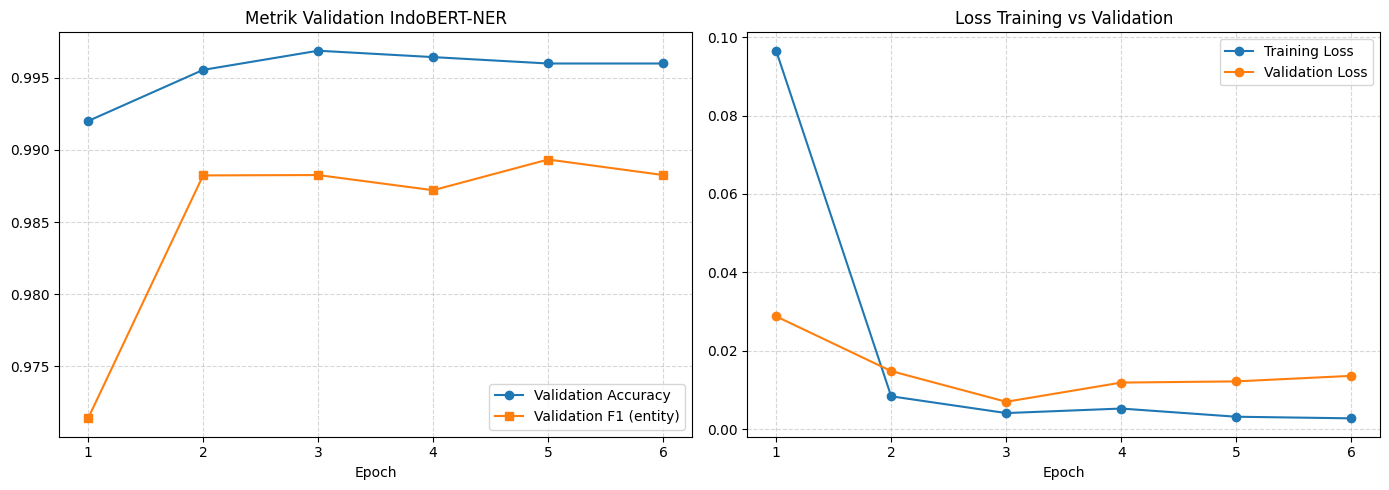

In [10]:
# ---------- kurva training (loss dan metrik validasi) ----------
if trainer is not None:
    hist = trainer.state.log_history
    tr = {round(h["epoch"]): h["loss"] for h in hist if "loss" in h and "eval_loss" not in h}
    ev_ = {round(h["epoch"]): h for h in hist if "eval_loss" in h}
    ep = sorted(ev_)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(ep, [ev_[e]["eval_accuracy"] for e in ep], "o-", label="Validation Accuracy")
    ax1.plot(ep, [ev_[e]["eval_f1"] for e in ep], "s-", label="Validation F1 (entity)")
    ax1.set_title("Metrik Validation IndoBERT-NER"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True, ls="--", alpha=.5)
    ax2.plot(sorted(tr), [tr[e] for e in sorted(tr)], "o-", label="Training Loss")
    ax2.plot(ep, [ev_[e]["eval_loss"] for e in ep], "o-", label="Validation Loss")
    ax2.set_title("Loss Training vs Validation"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True, ls="--", alpha=.5)
    plt.tight_layout(); plt.savefig("kurva_training_ner.png", dpi=150); plt.show()
else:
    print("Model dimuat tanpa training, kurva dilewati.")

## 5. Evaluasi IndoBERT-NER: Precision, Recall, F1, dan confusion matrix
- **P/R/F1** dihitung entity-level (seqeval): sebuah span benar hanya jika batas **dan** labelnya tepat.
- **Confusion matrix** dihitung token-level: baris = label sebenarnya, kolom = prediksi.
  `B-` dan `I-` yang tertukar berarti batas span meleset; `O` yang tertukar dengan `B/I` berarti kata pengisi dianggap khasiat atau khasiat terlewat.
- Dua set uji dilaporkan **terpisah**. Set khasiat + sintetis mudah (hampir semua kata adalah khasiat); **pertanyaan tulisan tangan** adalah angka yang paling jujur.

 Test: dataset + sintetis (entity-level, per tipe entitas)
               precision    recall  f1-score   support

       JENIS     1.0000    1.0000    1.0000        53
   KANDUNGAN     0.8986    0.9841    0.9394       252
     KHASIAT     0.9960    1.0000    0.9980       252

   micro avg     0.9502    0.9928    0.9710       557
   macro avg     0.9649    0.9947    0.9791       557
weighted avg     0.9523    0.9928    0.9717       557

 Pertanyaan tulisan tangan (entity-level, per tipe entitas)
               precision    recall  f1-score   support

       JENIS     1.0000    1.0000    1.0000         7
   KANDUNGAN     1.0000    1.0000    1.0000        14
     KHASIAT     0.7143    0.7143    0.7143        28

   micro avg     0.8367    0.8367    0.8367        49
   macro avg     0.9048    0.9048    0.9048        49
weighted avg     0.8367    0.8367    0.8367        49

                  Set uji   n  Precision  Recall     F1
 Test: dataset + sintetis 241     0.9502  0.9928 0.9710
Perta

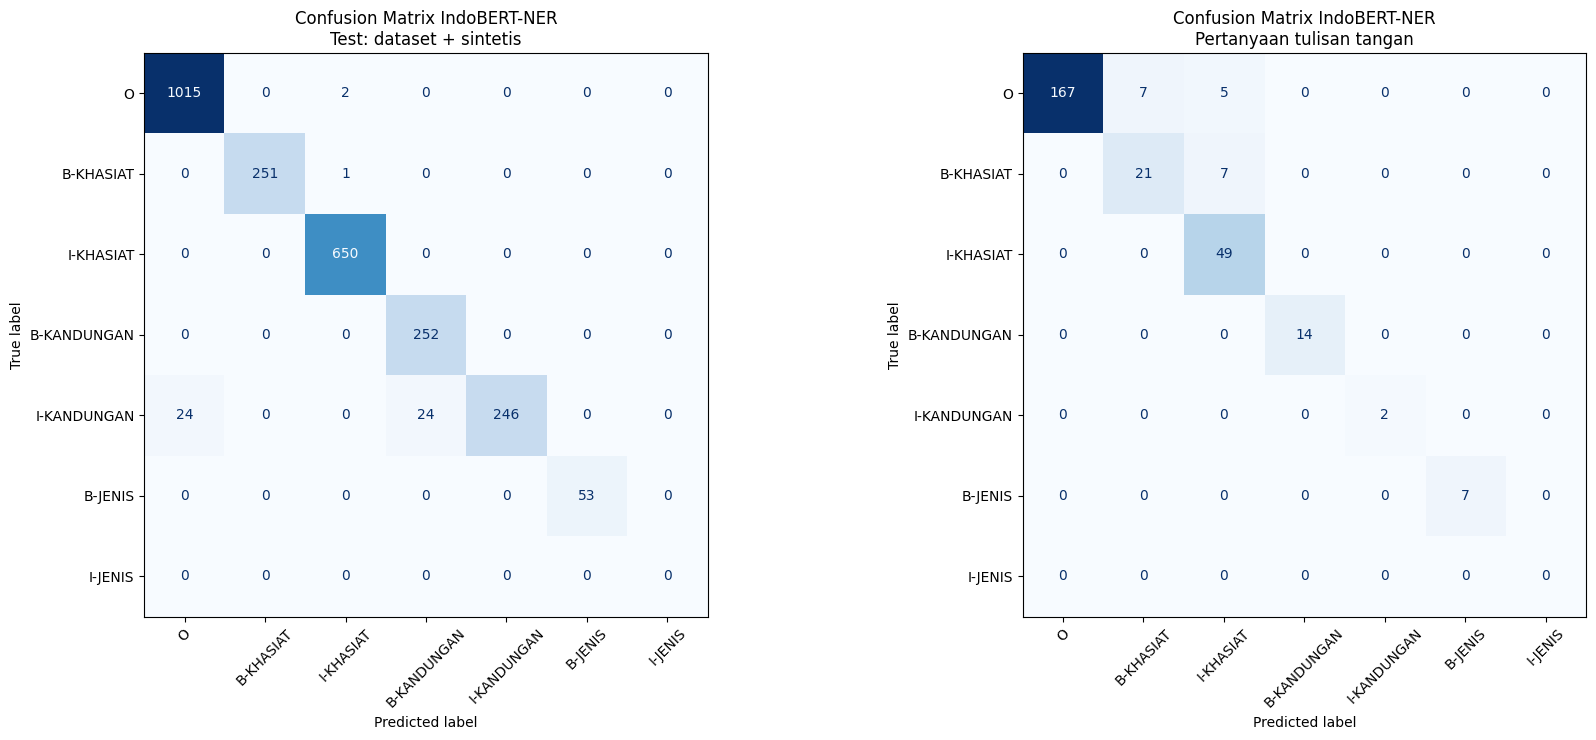


 Test: dataset + sintetis (token-level)
              precision    recall  f1-score   support

           O     0.9769    0.9980    0.9874      1017
   B-KHASIAT     1.0000    0.9960    0.9980       252
   I-KHASIAT     0.9954    1.0000    0.9977       650
 B-KANDUNGAN     0.9130    1.0000    0.9545       252
 I-KANDUNGAN     1.0000    0.8367    0.9111       294
     B-JENIS     1.0000    1.0000    1.0000        53
     I-JENIS     0.0000    0.0000    0.0000         0

    accuracy                         0.9797      2518
   macro avg     0.8408    0.8330    0.8355      2518
weighted avg     0.9808    0.9797    0.9792      2518


 Pertanyaan tulisan tangan (token-level)
              precision    recall  f1-score   support

           O     1.0000    0.9330    0.9653       179
   B-KHASIAT     0.7500    0.7500    0.7500        28
   I-KHASIAT     0.8033    1.0000    0.8909        49
 B-KANDUNGAN     1.0000    1.0000    1.0000        14
 I-KANDUNGAN     1.0000    1.0000    1.0000      

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report as sk_report

EVAL_SETS = {"Test: dataset + sintetis": test_rows, "Pertanyaan tulisan tangan": q_rows}
res, summary, per_type = {}, [], []
for name, rows in EVAL_SETS.items():
    gold = [r["tags"] for r in rows]
    pred = predict_tags(ner_model, [r["tokens"] for r in rows])
    res[name] = (gold, pred)
    summary.append({"Set uji": name, "n": len(rows), "Precision": precision_score(gold, pred),
                    "Recall": recall_score(gold, pred), "F1": f1_score(gold, pred)})
    print("=" * 60, "\n", name, "(entity-level, per tipe entitas)\n", classification_report(gold, pred, digits=4))
    rep = classification_report(gold, pred, digits=4, output_dict=True)
    for t in ENTITY_TYPES:
        if t in rep:
            per_type.append({"Set uji": name, "Entitas": t, "Precision": rep[t]["precision"], "Recall": rep[t]["recall"],
                             "F1": rep[t]["f1-score"], "Support": rep[t]["support"]})
summary = pd.DataFrame(summary).round(4)
summary.to_csv("hasil_ner.csv", index=False)
per_type = pd.DataFrame(per_type).round(4)
per_type.to_csv("hasil_ner_per_tipe.csv", index=False)
print(summary.to_string(index=False)); print(); print(per_type.to_string(index=False))

flat = lambda x: [t for seq in x for t in seq]
fig, axes = plt.subplots(1, len(res), figsize=(9 * len(res), 7.5))
for ax, (name, (gold, pred)) in zip(np.atleast_1d(axes), res.items()):
    cm = confusion_matrix(flat(gold), flat(pred), labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45)
    ax.set_title(f"Confusion Matrix IndoBERT-NER\n{name}")
plt.tight_layout(); plt.savefig("confusion_ner.png", dpi=150); plt.show()

for name, (gold, pred) in res.items():
    print("\n", name, "(token-level)")
    print(sk_report(flat(gold), flat(pred), labels=LABELS, digits=4, zero_division=0))

In [12]:
# analisis kesalahan pada pertanyaan tulisan tangan (khasiat, kandungan, jenis, kombinasi)
norm = lambda ents: sorted((l, t.lower()) for l, t in ents)
for r, qt in zip(q_rows, ev["qtype"]):
    pred = predict_spans(ner_model, r["text"])
    ok = norm(pred) == norm(r["spans"])
    print((("OK   " if ok else "SALAH") + f" [{qt}]"), r["text"], "\n       gold:", r["spans"], "| prediksi:", pred)

OK    [khasiat] Jamu apa yang bisa mengatasi keputihan? 
       gold: [('KHASIAT', 'mengatasi keputihan')] | prediksi: [('KHASIAT', 'mengatasi keputihan')]
SALAH [khasiat] Jamu untuk ibu menyusui supaya ASI lancar? 
       gold: [('KHASIAT', 'ASI lancar')] | prediksi: [('KHASIAT', 'ibu menyusui supaya ASI lancar')]
SALAH [khasiat] Anak saya susah makan, jamu apa yang cocok? 
       gold: [('KHASIAT', 'susah makan')] | prediksi: [('KHASIAT', 'Anak saya susah makan')]
SALAH [khasiat] Badan saya bau keringat, ada jamu yang bisa membantu? 
       gold: [('KHASIAT', 'bau keringat')] | prediksi: [('KHASIAT', 'Badan saya bau keringat'), ('KHASIAT', 'membantu')]
SALAH [khasiat] Jamu untuk perut nyeri saat datang bulan? 
       gold: [('KHASIAT', 'nyeri saat datang bulan')] | prediksi: [('KHASIAT', 'perut nyeri saat datang bulan')]
OK    [khasiat] Jamu apa untuk menambah tenaga dan stamina? 
       gold: [('KHASIAT', 'menambah tenaga dan stamina')] | prediksi: [('KHASIAT', 'menambah tenaga dan 

## 6. Ekstraksi entitas dari query + indeks retrieval
NER dipakai untuk menyaring query: kata pengisi dibuang, **semua entitas** (khasiat, kandungan, jenis) dipertahankan.
Jika NER tidak menemukan entitas, query asli dipakai (fallback).

In [13]:
@lru_cache(maxsize=None)
def ner_entities(query):
    return tuple(predict_spans(ner_model, query))              # ((label, teks), ...)

def ner_query(query):
    """Query diganti gabungan semua entitas; jika tidak ada entitas, query asli dipakai."""
    ents = ner_entities(query)
    return " ".join(t for _, t in ents) if ents else query

for q in ["Saya sering merasa lemah syahwat", "Jamu apa yang bisa bikin badan segar dan nafsu makan bertambah?",
          "Jamu yang mengandung kunyit untuk asam urat", "Ada jamu jenis serbuk untuk pegal linu?"]:
    print(f"{q!r}\n   entitas: {list(ner_entities(q))}\n   -> {ner_query(q)!r}")

'Saya sering merasa lemah syahwat'
   entitas: [('KHASIAT', 'Saya'), ('KHASIAT', 'sering merasa lemah syahwat')]
   -> 'Saya sering merasa lemah syahwat'
'Jamu apa yang bisa bikin badan segar dan nafsu makan bertambah?'
   entitas: [('KHASIAT', 'bikin badan segar dan nafsu makan bertambah')]
   -> 'bikin badan segar dan nafsu makan bertambah'
'Jamu yang mengandung kunyit untuk asam urat'
   entitas: [('KANDUNGAN', 'kunyit'), ('KHASIAT', 'asam urat')]
   -> 'kunyit asam urat'
'Ada jamu jenis serbuk untuk pegal linu?'
   entitas: [('JENIS', 'serbuk'), ('KHASIAT', 'pegal linu')]
   -> 'serbuk pegal linu'


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

STOPWORDS = set("""yang dan di ke dari untuk dengan pada ini itu atau juga serta dapat bisa agar supaya
akan adalah dalam saya anak ada apa jamu yg dgn utk karena sehingga lebih sangat bagi oleh""".split())
try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    _stem = StemmerFactory().create_stemmer().stem
    print("Stemming Sastrawi aktif")
except ImportError:
    _stem = lambda s: s
    print("Sastrawi tidak terpasang, stemming dilewati (opsional: pip install PySastrawi)")

def preprocess(text):
    text = re.sub(r"[^a-z0-9\s]", " ", str(text).lower())
    return " ".join(t for t in _stem(text).split() if t not in STOPWORDS)

docs, doc_ids = kb["doc_text"].tolist(), kb["doc_id"].tolist()
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_tfidf = tfidf.fit_transform([preprocess(d) for d in docs])

sbert = SentenceTransformer(SBERT_NAME)
E_docs = sbert.encode(docs, normalize_embeddings=True, show_progress_bar=False)
print("TF-IDF:", X_tfidf.shape, "| SBERT:", E_docs.shape)

Stemming Sastrawi aktif


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

TF-IDF: (322, 5783) | SBERT: (322, 768)


## 7. Hybrid retrieval
`skor = alpha * SBERT + (1 - alpha) * TF-IDF`, masing-masing dinormalisasi min-max per query
(**alpha = bobot SBERT**; kebalikan dari versi lama, yang tidak menormalisasi sehingga skala dua skor tidak sebanding).
Parameter `use_ner=True` mengganti query dengan hasil ekstraksi NER.

In [15]:
def minmax(x):
    x = np.asarray(x, dtype=float); rng = x.max() - x.min()
    return (x - x.min()) / rng if rng > 0 else np.zeros_like(x)

@lru_cache(maxsize=None)
def _qvec(q): return sbert.encode([q], normalize_embeddings=True)[0]

def scores_tfidf(q): return (X_tfidf @ tfidf.transform([preprocess(q)]).T).toarray().ravel()
def scores_sbert(q): return E_docs @ _qvec(q)

def retrieve(query, method="hybrid", k=TOP_K, alpha=0.5, use_ner=False):
    q = ner_query(query) if use_ner else query
    if method == "tfidf":   s = scores_tfidf(q)
    elif method == "sbert": s = scores_sbert(q)
    else:                   s = alpha * minmax(scores_sbert(q)) + (1 - alpha) * minmax(scores_tfidf(q))
    idx = np.argsort(-s)[:k]
    return [(doc_ids[i], float(s[i])) for i in idx]

def eval_retrieval(method, k=TOP_K, alpha=0.5, use_ner=False, qtypes=None):
    rr, prec, rec = [], [], []
    for _, r in ev.iterrows():
        if qtypes is not None and r["qtype"] not in qtypes: continue
        rel = set(r["relevant_ids"])
        if not rel: continue
        ranked = [d for d, _ in retrieve(r["question"], method, k=max(k, 50), alpha=alpha, use_ner=use_ner)]
        hits = [d in rel for d in ranked[:k]]
        first = next((i for i, d in enumerate(ranked, 1) if d in rel), None)
        rr.append(1 / first if first else 0.0); prec.append(sum(hits) / k); rec.append(sum(hits) / len(rel))
    return {"MRR": np.mean(rr), f"P@{k}": np.mean(prec), f"R@{k}": np.mean(rec)}

grid = np.round(np.arange(0.0, 1.01, 0.1), 2)
best_alpha = {}
for use_ner in (False, True):
    g = pd.DataFrame([{"alpha": a, **eval_retrieval("hybrid", alpha=a, use_ner=use_ner)} for a in grid])
    best_alpha[use_ner] = float(g.sort_values("MRR", ascending=False).iloc[0]["alpha"])
    print(f"Grid alpha (use_ner={use_ner}):"); print(g.round(3).to_string(index=False)); print()

rows = {}
for use_ner in (False, True):
    tag = "dengan NER" if use_ner else "tanpa NER"
    rows[f"TF-IDF ({tag})"]  = eval_retrieval("tfidf", use_ner=use_ner)
    rows[f"SBERT ({tag})"]   = eval_retrieval("sbert", use_ner=use_ner)
    rows[f"Hibrida ({tag}, a={best_alpha[use_ner]})"] = eval_retrieval("hybrid", alpha=best_alpha[use_ner], use_ner=use_ner)
retrieval_table = pd.DataFrame(rows).T.round(4)
retrieval_table.to_csv("hasil_retrieval.csv")
retrieval_table

Grid alpha (use_ner=False):
 alpha   MRR   P@5   R@5
   0.0 0.852 0.708 0.316
   0.1 0.855 0.703 0.317
   0.2 0.853 0.687 0.305
   0.3 0.828 0.687 0.304
   0.4 0.840 0.687 0.301
   0.5 0.814 0.682 0.288
   0.6 0.822 0.667 0.281
   0.7 0.791 0.615 0.260
   0.8 0.779 0.533 0.231
   0.9 0.684 0.472 0.206
   1.0 0.602 0.385 0.179

Grid alpha (use_ner=True):
 alpha   MRR   P@5   R@5
   0.0 0.856 0.708 0.334
   0.1 0.856 0.692 0.306
   0.2 0.846 0.682 0.301
   0.3 0.858 0.682 0.299
   0.4 0.862 0.677 0.297
   0.5 0.856 0.682 0.298
   0.6 0.861 0.667 0.289
   0.7 0.857 0.631 0.272
   0.8 0.820 0.585 0.278
   0.9 0.799 0.544 0.256
   1.0 0.734 0.431 0.186



,MRR,P@5,R@5
TF-IDF (tanpa NER),0.8516,0.7077,0.3161
SBERT (tanpa NER),0.6020,0.3846,0.1788
"Hibrida (tanpa NER, a=0.1)",0.8553,0.7026,0.3168
TF-IDF (dengan NER),0.8559,0.7077,0.3340
SBERT (dengan NER),0.7338,0.4308,0.1864
"Hibrida (dengan NER, a=0.4)",0.8622,0.6769,0.2972


In [16]:
# variasi K
for k in (1, 3, 5, 10):
    print(f"K={k}")
    print(pd.DataFrame({
        "TF-IDF":  eval_retrieval("tfidf", k=k, use_ner=True),
        "SBERT":   eval_retrieval("sbert", k=k, use_ner=True),
        "Hibrida": eval_retrieval("hybrid", k=k, alpha=best_alpha[True], use_ner=True),
    }).T.round(3).to_string(), "\n")

K=1
           MRR    P@1    R@1
TF-IDF   0.856  0.795  0.077
SBERT    0.734  0.615  0.092
Hibrida  0.862  0.795  0.079 

K=3
           MRR    P@3    R@3
TF-IDF   0.856  0.726  0.192
SBERT    0.734  0.496  0.136
Hibrida  0.862  0.735  0.223 

K=5
           MRR    P@5    R@5
TF-IDF   0.856  0.708  0.334
SBERT    0.734  0.431  0.186
Hibrida  0.862  0.677  0.297 

K=10
           MRR   P@10   R@10
TF-IDF   0.856  0.677  0.557
SBERT    0.734  0.362  0.295
Hibrida  0.862  0.654  0.488 



In [17]:
# performa retrieval per tipe pertanyaan (khasiat, kandungan, jenis, kombinasi), K=5
rows = {}
for qt in sorted(ev["qtype"].unique()):
    n_q = int((ev["qtype"] == qt).sum())
    for use_ner in (False, True):
        tag = "NER" if use_ner else "tanpa NER"
        for name, kw in [("TF-IDF", dict(method="tfidf")), ("SBERT", dict(method="sbert")),
                         ("Hibrida", dict(method="hybrid", alpha=best_alpha[use_ner]))]:
            rows[(qt, f"{name} ({tag})")] = {"n": n_q, **eval_retrieval(use_ner=use_ner, qtypes=[qt], **kw)}
by_type = pd.DataFrame(rows).T.round(3)
by_type.index.names = ["Tipe pertanyaan", "Metode"]
by_type.to_csv("hasil_retrieval_per_tipe.csv")
by_type

n    MRR    P@5    R@5
Tipe pertanyaan Metode                                        
jenis           TF-IDF (tanpa NER)    4.0  1.000  1.000  0.083
                SBERT (tanpa NER)     4.0  0.311  0.300  0.020
                Hibrida (tanpa NER)   4.0  1.000  0.950  0.078
                TF-IDF (NER)          4.0  1.000  1.000  0.083
                SBERT (NER)           4.0  0.750  0.550  0.038
                Hibrida (NER)         4.0  1.000  0.950  0.078
kandungan       TF-IDF (tanpa NER)    8.0  0.938  0.775  0.200
                SBERT (tanpa NER)     8.0  0.524  0.375  0.071
                Hibrida (tanpa NER)   8.0  0.938  0.775  0.206
                TF-IDF (NER)          8.0  0.938  0.725  0.193
                SBERT (NER)           8.0  0.660  0.375  0.076
                Hibrida (NER)         8.0  0.938  0.675  0.170
khasiat         TF-IDF (tanpa NER)   18.0  0.925  0.833  0.286
                SBERT (tanpa NER)    18.0  0.712  0.522  0.153
                Hibrida (tanpa NER)  18.0  0.926  0.833  0.286
                TF-IDF (NER)         18.0  0.925  0.856  0.291
                SBERT (NER)          18.0  0.829  0.567  0.162
                Hibrida (NER)        18.0  0.931  0.833  0.278
kombinasi       TF-IDF (tanpa NER)    9.0  0.563  0.267  0.583
                SBERT (tanpa NER)     9.0  0.581  0.156  0.398
                Hibrida (tanpa NER)   9.0  0.577  0.267  0.583
                TF-IDF (NER)          9.0  0.582  0.267  0.657
                SBERT (NER)           9.0  0.602  0.156  0.398
                Hibrida (NER)         9.0  0.597  0.244  0.546

## 8. Generasi jawaban dengan Gemini
Panggilan API memakai **retry dengan backoff** untuk error sementara (503 UNAVAILABLE, 429, 500). Error 503 yang kamu alami
berarti server Gemini sedang sibuk, bukan kesalahan kode. Jika model utama tetap gagal, model berikutnya di `GEMINI_MODELS` dicoba.
Isi `GEMINI_API_KEY` lewat environment variable, **jangan** menulis key langsung di notebook yang akan dibagikan.

In [18]:
from google import genai

GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY") or getpass.getpass("Masukkan GEMINI_API_KEY: ")
client = genai.Client(api_key=GEMINI_API_KEY)

RETRY_CODES = ("503", "UNAVAILABLE", "429", "RESOURCE_EXHAUSTED", "500", "INTERNAL", "DEADLINE")

def generate_gemini(prompt, max_retries=5, base_delay=3.0):
    last = "tidak ada model"
    for model_name in GEMINI_MODELS:
        for attempt in range(max_retries):
            try:
                r = client.models.generate_content(model=model_name, contents=prompt)
                if r.text:
                    return r.text.strip()
                last = f"{model_name}: respons kosong"; break
            except Exception as e:
                msg = str(e); last = f"{model_name}: {msg[:200]}"
                if any(c in msg for c in RETRY_CODES):
                    time.sleep(base_delay * 2 ** attempt + random.random()); continue
                break                                   # error lain (mis. 404 model tidak ada): coba model berikutnya
    return f"[GAGAL] {last}"

RAG_PROMPT = """Kamu adalah pakar kesehatan tradisional Jamu Madura yang ramah dan profesional.
Jawab pertanyaan pengguna dengan singkat (2-3 kalimat), jelas, dan faktual HANYA berdasarkan KONTEKS di bawah.
Sebut nama jamu yang relevan. Jika pertanyaan menyangkut kandungan atau jenis jamu, gunakan informasi tersebut dari konteks.
Jika konteks tidak memuat jawabannya, katakan bahwa informasinya tidak ditemukan.
Jangan memberi rekomendasi di luar konteks.

KONTEKS REFERENSI JAMU:
{context}

PERTANYAAN PENGGUNA:
{question}

JAWABAN:"""

_by_id = kb.set_index("doc_id")

def fmt_doc(d):
    """Satu entri konteks untuk Gemini: nama (jenis): khasiat + baris kandungan bila ada."""
    r = _by_id.loc[d]
    line = f"- {r['nama']}" + (f" (jenis: {r['jenis']})" if r["jenis"] else "") + f": {r['khasiat']}"
    return line + (f"\n  Kandungan: {r['kandungan']}" if r["kandungan"] else "")

def rag_pipeline(query, method="hybrid", use_ner=True, k=TOP_K, alpha=None):
    alpha = best_alpha[use_ner] if alpha is None else alpha
    hits = retrieve(query, method, k=k, alpha=alpha, use_ner=use_ner)
    context = "\n".join(fmt_doc(d) for d, _ in hits)
    answer = generate_gemini(RAG_PROMPT.format(context=context, question=query))
    return {"ner_query": ner_query(query) if use_ner else query, "hits": hits, "context": context, "answer": answer}

def chatbot():
    print("=" * 65, "\n CHATBOT RAG JAMU MADURA (IndoBERT-NER + Hybrid + Gemini)\n", "=" * 65)
    print("Ketik 'keluar' untuk mengakhiri.\n")
    while True:
        q = input("Pengguna : ").strip()
        if q.lower() in ("keluar", "exit", "q"):
            print("Chatbot: Terima kasih! Semoga sehat selalu dengan Jamu Madura."); break
        if not q: continue
        out = rag_pipeline(q)
        print(f"\n[LOG] keyword NER: {out['ner_query']} | dokumen teratas: {_by_id.loc[out['hits'][0][0], 'nama']}")
        print("\nChatbot :\n" + out["answer"] + "\n" + "=" * 65 + "\n")

# uji satu pertanyaan (jalankan chatbot() untuk mode interaktif)
demo = rag_pipeline("Saya sering merasa lemah syahwat")
print("Keyword NER:", demo["ner_query"]); print(demo["context"]); print("\n", demo["answer"])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Keyword NER: Saya sering merasa lemah syahwat
- Super Pria (jenis: pil): Menyembuhkan lemah syahwat dan impotensi pada laki laki, Menambah gairah bagi pria.
  Kandungan: Biji Benalu,batang tumbuhan, biji pinang 20%, kulit kering 20% Dan bahan lain sampai 100%
- Sehat Pria /Perkasa (Tambah Syahwat) (jenis: kapsul): Menyembuhkan lemah syahwat dan impotensi pada laki laki. - Menambah gairah bagi pria saat berhubungan suami istri.
  Kandungan: Cuscutae semen (untuk vita*litas pria) 20% • Terminalis rhizoma (batang tumbuhan) 20% • Areca semen (biji pinang) 20% • Cinnamomum cortex (kulit kering ) 20% Dan bahan lain sampai 100%
- Jamu Kuat Helbeh Mutiara (jenis: cair): Menghilangkan rasa letih, Menambah tenaga /energi, Mengobati lemah syahwat, Mengobati jantung berdebar, Menghilangkan sakit pinggang, Menghilangkan rematik/encok, Mengurangi asam urat, Menghancurkan batu ginjal
  Kandungan: jinten, kapulaga, cabe jamu, kencur dll
- Kapsul Helben Super (jenis: kapsul): Memperbaiki gairah seksual

## 9. Evaluasi kualitas jawaban RAG (BLEU, ROUGE, BERTScore)
Metrik dihitung pada **semua pertanyaan** di `eval_set.csv` dengan **jawaban Gemini yang sebenarnya**, untuk empat konfigurasi:
TF-IDF, SBERT, Hibrida, dan Hibrida + NER. Hasil API disimpan di `gen_cache.json`, jadi jika terhenti di tengah jalan
(misalnya 503), menjalankan ulang sel ini hanya memanggil yang belum selesai.

Kualitas skor bergantung pada `reference_answer`. Referensi bawaan sangat singkat; **tulis ulang sendiri** sebagai kalimat
jawaban lengkap yang kamu anggap benar agar skornya bermakna.

In [19]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

GEN_CONDITIONS = {"TF-IDF": ("tfidf", False), "SBERT": ("sbert", False),
                  "Hibrida": ("hybrid", False), "Hibrida + NER": ("hybrid", True)}
CACHE_FILE = "gen_cache_kandungan_jenis.json"   # cache baru: konteks Gemini berubah, jangan pakai gen_cache.json lama
cache = json.load(open(CACHE_FILE, encoding="utf-8")) if os.path.exists(CACHE_FILE) else {}

for cond, (method, use_ner) in GEN_CONDITIONS.items():
    for _, r in ev.iterrows():
        key = f"{cond}||{r['question']}"
        if key in cache: continue
        out = rag_pipeline(r["question"], method=method, use_ner=use_ner)
        if out["answer"].startswith("[GAGAL]"):
            print("Gagal:", key[:60], "->", out["answer"][:120]); continue
        cache[key] = out["answer"]
        json.dump(cache, open(CACHE_FILE, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
        time.sleep(GEN_SLEEP)
print("Jawaban tersimpan:", len(cache), "dari", len(GEN_CONDITIONS) * len(ev))

Gagal: TF-IDF||Jamu apa yang mengandung jahe? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, p
Gagal: TF-IDF||Jamu apa yang mengandung temulawak? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, p
Gagal: TF-IDF||Jamu apa yang mengandung daun sirih? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, p
Gagal: TF-IDF||Jamu apa yang mengandung kapulaga? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, p
Gagal: TF-IDF||Jamu apa yang mengandung dll? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, p
Gagal: TF-IDF||Jamu apa yang mengandung gula? -> [GAGAL] gemini-3.6-flash: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Y

In [20]:
def words(s): return re.findall(r"\w+", str(s).lower())

def rouge_n(ref, hyp, n):
    r = [tuple(ref[i:i + n]) for i in range(len(ref) - n + 1)]
    h = [tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1)]
    if not r or not h: return 0.0
    o = sum((Counter(r) & Counter(h)).values())
    p, rc = o / len(h), o / len(r)
    return 2 * p * rc / (p + rc) if p + rc else 0.0

def rouge_l(ref, hyp):
    if not ref or not hyp: return 0.0
    dp = [[0] * (len(hyp) + 1) for _ in range(len(ref) + 1)]
    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            dp[i][j] = dp[i-1][j-1] + 1 if ref[i-1] == hyp[j-1] else max(dp[i-1][j], dp[i][j-1])
    l = dp[-1][-1]; p, rc = l / len(hyp), l / len(ref)
    return 2 * p * rc / (p + rc) if p + rc else 0.0

smooth = SmoothingFunction().method1
try:
    from bert_score import score as bertscore
except ImportError:
    bertscore = None; print("bert-score tidak terpasang: pip install bert-score")

gen_rows = []
for cond in GEN_CONDITIONS:
    pairs = [(r["reference_answer"], cache[f"{cond}||{r['question']}"]) for _, r in ev.iterrows()
             if f"{cond}||{r['question']}" in cache]
    if not pairs: continue
    refs, preds = [p[0] for p in pairs], [p[1] for p in pairs]
    row = {"Konfigurasi": cond, "n": len(pairs),
           "BLEU": np.mean([sentence_bleu([words(a)], words(b), smoothing_function=smooth) for a, b in pairs]),
           "ROUGE-1": np.mean([rouge_n(words(a), words(b), 1) for a, b in pairs]),
           "ROUGE-2": np.mean([rouge_n(words(a), words(b), 2) for a, b in pairs]),
           "ROUGE-L": np.mean([rouge_l(words(a), words(b)) for a, b in pairs])}
    if bertscore is not None:
        try:
            _, _, F = bertscore(preds, refs, model_type=BERTSCORE_MODEL[0], num_layers=BERTSCORE_MODEL[1], verbose=False)
            row["BERTScore-F1"] = F.mean().item()
        except Exception as e:
            print("BERTScore gagal:", str(e)[:150])
    gen_rows.append(row)

gen_table = pd.DataFrame(gen_rows).set_index("Konfigurasi").round(4)
gen_table.to_csv("hasil_generasi.csv")
gen_table

Exception in thread Thread-auto_conversion:
Traceback (most recent call last):
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 101, in map_httpcore_exceptions
    yield
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 250, in handle_request
    resp = self._pool.handle_request(req)
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 256, in handle_request
    raise exc from None
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 236, in handle_request
    response = connection.handle_request(
        pool_request.request
    )
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection.py", line 101, in handle_request
    raise exc
  File "c:\Users\Asus\AppData\Local\Prog

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Exception in thread Thread-auto_conversion:
Traceback (most recent call last):
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 101, in map_httpcore_exceptions
    yield
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 250, in handle_request
    resp = self._pool.handle_request(req)
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 256, in handle_request
    raise exc from None
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 236, in handle_request
    response = connection.handle_request(
        pool_request.request
    )
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection.py", line 101, in handle_request
    raise exc
  File "c:\Users\Asus\AppData\Local\Prog

BERTScore gagal: int too big to convert


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Exception in thread Thread-auto_conversion:
Traceback (most recent call last):
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 101, in map_httpcore_exceptions
    yield
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpx\_transports\default.py", line 250, in handle_request
    resp = self._pool.handle_request(req)
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 256, in handle_request
    raise exc from None
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection_pool.py", line 236, in handle_request
    response = connection.handle_request(
        pool_request.request
    )
  File "c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\httpcore\_sync\connection.py", line 101, in handle_request
    raise exc
  File "c:\Users\Asus\AppData\Local\Prog

... (3 outputs left out)

BERTScore gagal: int too big to convert


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERTScore gagal: int too big to convert


,n,BLEU,ROUGE-1,ROUGE-2,ROUGE-L
Konfigurasi,,,,,
TF-IDF,19,0.0169,0.1538,0.0534,0.1298
SBERT,2,0.0379,0.1996,0.0727,0.1443
Hibrida,14,0.0399,0.2278,0.1261,0.2144
Hibrida + NER,1,0.0051,0.1176,0.0000,0.1176


## Catatan: hal yang perlu kamu verifikasi
1. **`ner_annotations.csv`**: hasil aturan otomatis, pasti ada yang meleset (misalnya span yang masih memuat kata "Membantu" atau
   klausa terlalu panjang). Perbaiki kolom `spans`, lalu jalankan ulang dari bagian 3. Tanpa ini, F1 NER tidak bisa dipercaya.
2. **`eval_set.csv`**: perluas ke 50-100 pertanyaan; periksa dokumen relevan, `ner_spans`, dan tulis `reference_answer` lengkap.
   Label relevansi lewat kata kunci menguntungkan TF-IDF, jadi sertakan pertanyaan dengan bahasa awam yang tidak memakai kata persis dari khasiat.
3. **Encoder SBERT**: `indobenchmark/indobert-base-p1` mentah tidak dilatih untuk kemiripan kalimat, sehingga skor cosine-nya sempit dan
   kurang membedakan. Karena itu defaultnya `LazarusNLP/all-indobert-base-v4` (sentence-transformers). Cek model card-nya untuk memastikan backbone
   sebelum menyebutnya "berbasis IndoBERT" di skripsi. Jika pembimbing mengharuskan IndoBERT mentah, ubah `SBERT_NAME` dan laporkan perbedaannya sebagai ablasi.
4. **Nama model Gemini** pada `GEMINI_MODELS` bisa berubah; model yang tidak ada akan dilewati otomatis. Daftar model yang tersedia di akunmu bisa dilihat lewat `client.models.list()`.
5. **Recall@K kecil secara alami** untuk pertanyaan dengan banyak dokumen relevan (misalnya keputihan punya puluhan). Itu batas matematis K, bukan kelemahan sistem.
6. **Kolom JENIS dan KANDUNGAN dipakai di semua tahap**: dokumen retrieval, label NER (3 entitas: KHASIAT, KANDUNGAN, JENIS), data sintetis dan kombinasi,
   set evaluasi, `ner_query`, dan konteks Gemini. Label NER berubah (3 -> 7), jadi model **harus dilatih ulang** (`NER_DIR = "ner_model_v2"`).
   Jalankan ulang dari bagian 1; semua hasil lama tidak sebanding dengan hasil baru. Untuk ablasi, bandingkan `USE_JENIS` / `USE_KANDUNGAN` = False vs True.
7. **`ner_annotations_extra.csv`** (kandungan dan jenis) hasil aturan otomatis: periksa kolom `spans` (bahan yang tergabung, takaran seperti "10 gram", atau jenis yang terpecah salah).
   Pisahan "dan" bisa salah bila nama bahan memuat kata "dan".
8. **`eval_set_kandungan_jenis.csv`** dibuat otomatis dari bahan dan jenis yang paling sering muncul, dengan relevansi berbasis kecocokan item persis. Itu menguntungkan TF-IDF.
   Tambahkan pertanyaan tulisan sendiri (bahasa awam, beberapa entitas sekaligus) sebelum menarik kesimpulan.
9. **Skor NER untuk JENIS hampir pasti tinggi** karena nilainya sedikit dan berulang (kosakata tertutup), sehingga muncul di train maupun test. Jangan dibaca sebagai kemampuan generalisasi.
   Hasil per entitas ada di `hasil_ner_per_tipe.csv`; retrieval per tipe pertanyaan di `hasil_retrieval_per_tipe.csv`.
10. **Pemakaian Gemini naik**: set evaluasi kini lebih banyak pertanyaan × 4 konfigurasi. Cache `gen_cache_kandungan_jenis.json` membuat sel bagian 9 bisa dilanjutkan jika terhenti (429/503).
11. **`reference_answer` pada `eval_set_kandungan_jenis.csv` sangat singkat** (otomatis), sehingga BLEU/ROUGE/BERTScore untuk pertanyaan tipe ini kurang bermakna. Tulis ulang sebagai kalimat jawaban lengkap.
12. **Nilai kosong di JENIS dan KANDUNGAN diisi "Tidak ada".** Dokumen dan konteks Gemini memuat tulisan itu apa adanya (mis. `Kandungan: Tidak ada`),
    jadi Gemini bisa membacanya sebagai "tidak ada data kandungan", bukan "jamu ini tanpa bahan apa pun". Jika itu menyesatkan, ubah `NO_VALUE` di sel bagian 1.
    Baris "Tidak ada" sengaja tidak diberi label NER dan tidak dipakai membuat pertanyaan evaluasi.
